### BCSE432E Reinforcement Learning Lab: L29+L30
### Lab Assignment 5

### Delivery Drone Q-Learning

### Name: Yashvanth Karunakaran (23BAI1589)

Notebook Link: [https://github.com/Yashvanthk05/RL/blob/main/23BAI1589_LAB-5.ipynb](https://github.com/Yashvanthk05/RL/blob/main/23BAI1589_LAB-5.ipynb)

### AIM:
To Implement a custom 16 x 16 grid-world environment for a delivery drone and train a tabular Q-Learning agent

### Problem:
environment has Battery constraints, Recharging stations, Two packages with sequential delivery constraints, Obstacles, stochastic wind region, Positive and negative rewards


Q-Learning agent uses an epsilon-greedy policy with exponential decay and learns an optimal policy for completing both deliveries

### Hyperparameters

In [1]:
GRID_SIZE = 16
MAX_BATTERY = 40

ALPHA = 0.1
GAMMA = 0.99

EPSILON = 1.0
EPSILON_MIN = 0.01
LAMBDA = 0.00008

EPISODES = 10000
EVAL_INTERVAL = 500
EVAL_EPISODES = 100

# Actions
UP, DOWN, LEFT, RIGHT = 0, 1, 2, 3
ACTIONS = [UP, DOWN, LEFT, RIGHT]

### Drone Environment

In [ ]:
import random

class DroneEnv:

    def __init__(self):
        self.start = (0, 0)

        self.recharge = [(4, 4), (11, 11)]

        self.p1_pick = (0, 15)
        self.p1_drop = (15, 0)

        self.p2_pick = (15, 15)
        self.p2_drop = (7, 12)

        self.obstacles = {
            (3, 8), (4, 8), (5, 8),
            (10, 2), (10, 3), (10, 4), (10, 5)
        }

        self.wind = [
            (r, c)
            for r in range(6, 10)
            for c in range(6, 10)
        ]

        self.reset()

    def reset(self):
        self.pos = self.start
        self.battery = MAX_BATTERY

        # 0 = P1 not picked
        # 1 = carrying P1
        # 2 = P1 delivered
        # 3 = carrying P2
        # 4 = P2 delivered
        self.stage = 0

        return self.state()

    def state(self):
        # row, column, battery level, stage
        return self.pos[0], self.pos[1], self.battery, self.stage

    def _subgoal(self):
        if self.stage == 0: return self.p1_pick
        if self.stage == 1: return self.p1_drop
        if self.stage == 2: return self.p2_pick
        if self.stage == 3: return self.p2_drop
        return self.pos

    def step(self, action):
        r, c = self.pos
        old_dist = abs(r - self._subgoal()[0]) + abs(c - self._subgoal()[1])

        if action == UP:
            new_pos = (r - 1, c)
        elif action == DOWN:
            new_pos = (r + 1, c)
        elif action == LEFT:
            new_pos = (r, c - 1)
        else:
            new_pos = (r, c + 1)

        # Wind: 25% chance of moving down
        if self.pos in self.wind and random.random() < 0.25:
            new_pos = (r + 1, c)

        reward = -1
        done = False

        # Wall / obstacle
        if new_pos[0] < 0 or new_pos[0] >= GRID_SIZE or new_pos[1] < 0 or new_pos[1] >= GRID_SIZE or new_pos in self.obstacles:
            reward -= 10
        else:
            self.pos = new_pos

        # Battery cost
        self.battery -= 1

        # Out of battery
        if self.battery <= 0:
            self.battery = 0
            reward -= 200
            done = True

        # Recharge
        if self.pos in self.recharge and self.battery < MAX_BATTERY:
            reward += 5
            self.battery = MAX_BATTERY

        # Package 1 pickup
        if self.stage == 0 and self.pos == self.p1_pick:
            self.stage = 1
            reward += 50

        # Package 1 delivery
        if self.stage == 1 and self.pos == self.p1_drop:
            self.stage = 2
            reward += 500

        # Package 2 pickup
        if self.stage == 2 and self.pos == self.p2_pick:
            self.stage = 3
            reward += 50

        # Package 2 delivery
        if self.stage == 3 and self.pos == self.p2_drop:
            self.stage = 4
            reward += 1500
            done = True

        if not done and self.stage < 4:
            nr, nc = self.pos
            new_dist = abs(nr - self._subgoal()[0]) + abs(nc - self._subgoal()[1])
            reward += (old_dist - new_dist)

        return self.state(), reward, done


### Creating Environment

In [3]:
env = DroneEnv()

print("Initial state:", env.reset())

Initial state: (0, 0, 40, 0)


### Q-Table

In [4]:
from collections import defaultdict
Q = defaultdict(float)

### Epsilon-Greedy

epsilon_t = max(0.01,1e-0.00008t)

In [5]:
import math
import numpy as np

def get_epsilon(t):
    return max(EPSILON_MIN, EPSILON * math.exp(-LAMBDA * t))

def choose_action(state, epsilon):
    # Exploration
    if random.random() < epsilon:
        return random.choice(ACTIONS)

    # Exploitation with random tie-breaking
    q_values = [Q[(state, a)] for a in ACTIONS]
    max_val = max(q_values)
    best_actions = [a for a in ACTIONS if Q[(state, a)] == max_val]

    return random.choice(best_actions)


### Q-Learning Training

In [6]:
rewards=[]
evaluation_rewards=[]
completion_rates=[]
evaluation_episodes=[]

step_count=0

for episode in range(1, EPISODES + 1):
    state=env.reset()
    total_reward=0
    done=False
    epsilon=get_epsilon(episode)

    for step in range(2000):
        action=choose_action(state,epsilon)

        next_state, reward, done=env.step(action)

        old_q=Q[(state, action)]

        if done:
            target=reward
        else:
            best_next_q=max(Q[(next_state, a)] for a in ACTIONS)

            target=reward + GAMMA * best_next_q

        Q[(state, action)]=old_q + ALPHA*(target-old_q)

        state=next_state
        total_reward+=reward
        step_count+=1

        if done:
            break

    rewards.append(total_reward)

    # evaluation at 500 interval
    if episode % EVAL_INTERVAL==0:
        eval_rewards=[]
        successes=0

        for _ in range(EVAL_EPISODES):
            state=env.reset()
            total=0
            done=False

            for _ in range(2000):
                action=choose_action(state,0)
                state,reward,done=env.step(action)
                total+=reward
                if done:
                    break

            eval_rewards.append(total)

            if env.stage==4:
                successes+=1

        mean_reward=np.mean(eval_rewards)

        completion_rate=(successes/EVAL_EPISODES)*100

        evaluation_episodes.append(episode)
        evaluation_rewards.append(mean_reward)
        completion_rates.append(completion_rate)

        print(f"Episode {episode}: Mean Reward={mean_reward:.2f}, Completion Rate={completion_rate:.2f}%")


Episode 500: Mean Reward=-269.90, Completion Rate=0.00%
Episode 1000: Mean Reward=-288.36, Completion Rate=0.00%
Episode 1500: Mean Reward=-285.73, Completion Rate=0.00%
Episode 2000: Mean Reward=-273.63, Completion Rate=0.00%
Episode 2500: Mean Reward=-272.54, Completion Rate=0.00%
Episode 3000: Mean Reward=-266.00, Completion Rate=0.00%
Episode 3500: Mean Reward=-260.00, Completion Rate=0.00%
Episode 4000: Mean Reward=-254.40, Completion Rate=0.00%
Episode 4500: Mean Reward=-239.00, Completion Rate=0.00%
Episode 5000: Mean Reward=-237.60, Completion Rate=0.00%
Episode 5500: Mean Reward=-256.70, Completion Rate=0.00%
Episode 6000: Mean Reward=-235.74, Completion Rate=0.00%
Episode 6500: Mean Reward=-240.90, Completion Rate=0.00%
Episode 7000: Mean Reward=-208.70, Completion Rate=0.00%
Episode 7500: Mean Reward=-244.60, Completion Rate=0.00%
Episode 8000: Mean Reward=-244.70, Completion Rate=0.00%
Episode 8500: Mean Reward=-245.20, Completion Rate=0.00%
Episode 9000: Mean Reward=-240.0

### Training Reward Plot

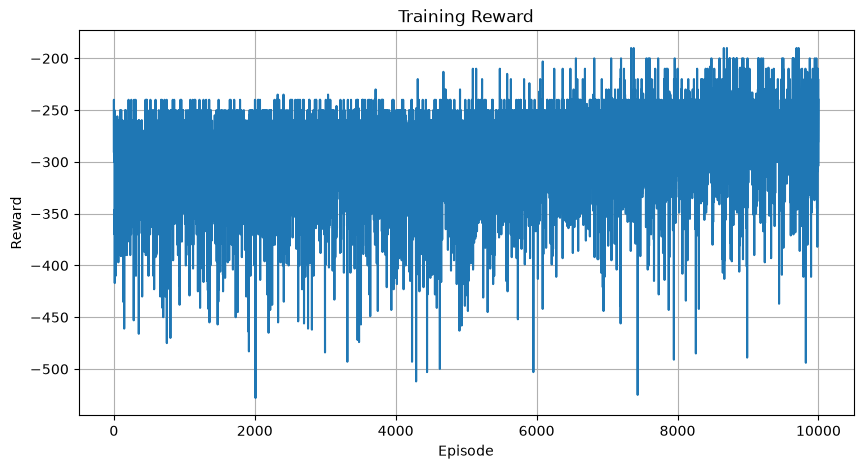

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(rewards)

plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Training Reward")

plt.grid()
plt.show()

### Required Mean Reward Plot

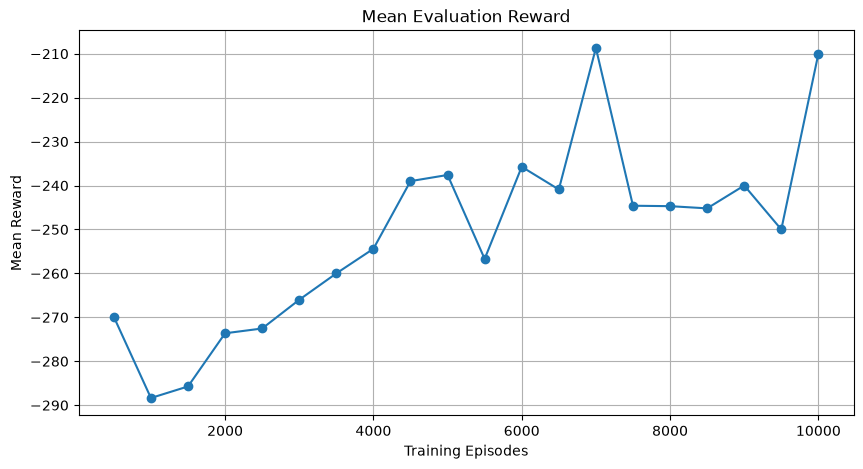

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(evaluation_episodes,evaluation_rewards,marker="o")

plt.xlabel("Training Episodes")
plt.ylabel("Mean Reward")
plt.title("Mean Evaluation Reward")

plt.grid()
plt.show()

### Required Completion Rate Plot

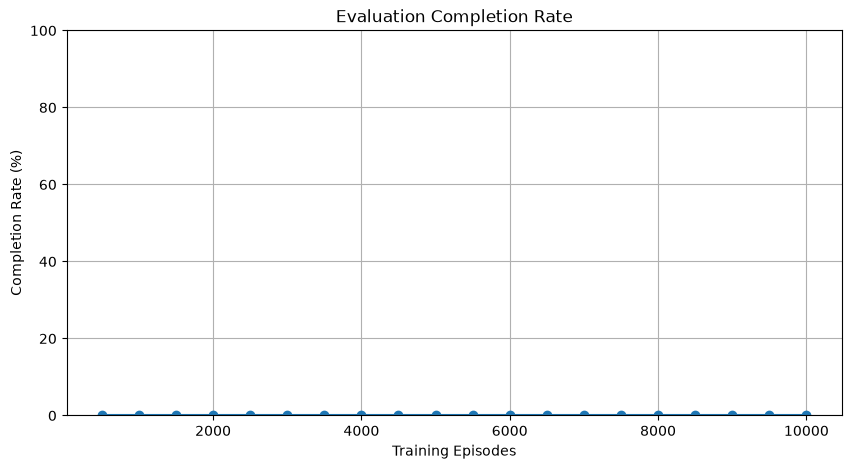

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(evaluation_episodes,completion_rates,marker="o")

plt.xlabel("Training Episodes")
plt.ylabel("Completion Rate (%)")
plt.title("Evaluation Completion Rate")

plt.ylim(0, 100)

plt.grid()
plt.show()

### Results

In [10]:
print("Mean Reward:",evaluation_rewards[-1])

print("Completion Rate:",completion_rates[-1],"%")

print("Q-table Size:",len(Q))

Mean Reward: -210.0
Completion Rate: 0.0 %
Q-table Size: 33272


### Observations

Through the implementation of this lab, several key challenges and observations regarding Tabular Q-learning in complex, sparse-reward environments


#### Sparse Reward Problem
The environment requires a highly specific sequence of actions (over 70 steps) to complete both deliveries. Without intermediate rewards for picking up packages or moving closer to subgoals, the probability of a random agent finding the successful path in the initial exploration phase is astronomically low

#### Battery Constraints
strict battery limit B_max = 40 necessitates strategic deviations to recharge stations at (4,4) and (11,11). The agent must learn to interrupt its path to the delivery goal to recharge, adding a layer of temporal complexity that is difficult for basic Q-learning to master without 'forward planning' or targeted reward shaping


#### Exploration vs. Exploitation (Epsilon Decay)
specified exponential decay formula (lambda = 0.00008) highlights the delicate balance of exploration


### Conclusion
this experiment demonstrates that while Tabular Q-learning is a powerful foundational algorithm, scaling it to sequential multi-stage tasks with resource constraints requires careful environment design, dense reward shaping, and finely-tuned exploration strategies.